In [115]:
import pandas as pd
import sqlite3
from pathlib import Path

raw_dir = Path("../data/raw")
conn = sqlite3.connect("../data/nhanes.db")

for f in sorted(raw_dir.iterdir()):
    if f.suffix.lower() !=".xpt":
        continue
    df = pd.read_sas(f)
    table = f.stem.lower()
    df.to_sql(table, conn, if_exists="replace", index=False)
    print(f"{table}: {len(df)} rows, {len(df.columns)} columns")


bmx_j: 8704 rows, 21 columns
demo_j: 9254 rows, 46 columns
ghb_j: 6401 rows, 2 columns
hscrp_j: 8366 rows, 3 columns
paq_j: 5856 rows, 17 columns
smq_j: 6724 rows, 37 columns


In [116]:
print(pd.read_sql("SELECT name FROM sqlite_master WHERE type='table'", conn))
pd.read_sql("SELECT * FROM paq_j LIMIT 5", conn).columns.tolist()

       name
0  analysis
1     bmx_j
2    demo_j
3     ghb_j
4   hscrp_j
5     paq_j
6     smq_j


['SEQN',
 'PAQ605',
 'PAQ610',
 'PAD615',
 'PAQ620',
 'PAQ625',
 'PAD630',
 'PAQ635',
 'PAQ640',
 'PAD645',
 'PAQ650',
 'PAQ655',
 'PAD660',
 'PAQ665',
 'PAQ670',
 'PAD675',
 'PAD680']

In [117]:
query = """
SELECT
    d.SEQN,
    d.RIAGENDR,
    d.RIDAGEYR,
    d.WTMEC2YR,
    d.SDMVPSU,
    d.SDMVSTRA,
    b.BMXBMI,
    h.LBXHSCRP,
    g.LBXGH,
    s.SMQ020,
    p.PAQ605,
    p.PAD615,
    p.PAQ620,
    p.PAD630,
    p.PAQ635,
    p.PAD645,
    p.PAQ650,
    p.PAD660,
    p.PAQ665,
    p.PAD675,
    p.PAD680
FROM demo_j AS d
LEFT JOIN bmx_j AS b ON d.SEQN = b.SEQN
LEFT JOIN ghb_j AS g ON d.SEQN = g.SEQN
LEFT JOIN hscrp_j AS h ON d.SEQN = h.SEQN
LEFT JOIN paq_j AS p ON d.SEQN = p.SEQN
LEFT JOIN smq_j AS s ON d.SEQN = s.SEQN
WHERE d.RIDAGEYR >= 18
    AND h.LBXHSCRP IS NOT NULL
    AND g.LBXGH IS NOT NULL
LIMIT 5
"""

pd.read_sql(query, conn)

,SEQN,RIAGENDR,RIDAGEYR,WTMEC2YR,SDMVPSU,SDMVSTRA,BMXBMI,LBXHSCRP,LBXGH,SMQ020,...,PAD615,PAQ620,PAD630,PAQ635,PAD645,PAQ650,PAD660,PAQ665,PAD675,PAD680
0,93705.0,2.0,66.0,8338.419786,2.0,145.0,31.7,2.72,6.2,1.0,...,None,2.0,NaN,2.0,NaN,2.0,NaN,1.0,60.0,300.0
1,93706.0,1.0,18.0,8723.439814,2.0,134.0,21.5,0.74,5.2,2.0,...,None,2.0,NaN,1.0,45.0,2.0,NaN,1.0,30.0,240.0
2,93708.0,2.0,66.0,14372.488765,2.0,138.0,23.7,1.83,6.2,2.0,...,None,2.0,NaN,2.0,NaN,2.0,NaN,1.0,30.0,120.0
3,93709.0,2.0,75.0,12277.556662,1.0,136.0,38.9,6.94,6.3,1.0,...,None,1.0,180.0,2.0,NaN,2.0,NaN,2.0,NaN,600.0
4,93711.0,1.0,56.0,12390.919724,2.0,134.0,21.3,0.82,5.7,2.0,...,None,2.0,NaN,1.0,60.0,1.0,60.0,1.0,30.0,420.0


In [118]:
conn.execute("DROP TABLE IF EXISTS analysis")
conn.execute("""
CREATE TABLE analysis AS
SELECT
    d.SEQN AS seqn,
    d.RIDAGEYR AS age,
    CASE
        WHEN d.RIDAGEYR < 40 THEN '18-39'
        WHEN d.RIDAGEYR < 60 THEN '40-59'
        WHEN d.RIDAGEYR < 80 THEN '60-79'
        ELSE '80+'
    END AS age_group,
    CASE
        WHEN d.RIAGENDR = 1 THEN 'male'
        WHEN d.RIAGENDR = 2 THEN 'female'
    END AS sex,
    b.BMXBMI AS bmi,
    c.LBXHSCRP AS crp,
    g.LBXGH AS hba1c,
    CASE
        WHEN p.PAQ605 = 2 THEN 0
        WHEN p.PAQ605 = 1 AND p.PAD615 IS NOT NULL
            AND p.PAQ610 BETWEEN 1 AND 7
            AND p.PAD615 < 7777 THEN p.PAQ610 * p.PAD615
        ELSE NULL
    END AS vigorous_work_minutes,
    CASE
        WHEN p.PAQ620 = 2 THEN 0
        WHEN p.PAQ620 = 1 AND p.PAD630 IS NOT NULL
            AND p.PAQ625 BETWEEN 1 AND 7
            AND p.PAD630 < 7777 THEN p.PAQ625 * p.PAD630
        ELSE NULL
    END AS moderate_work_minutes,
    CASE
        WHEN p.PAQ635 = 2 THEN 0
        WHEN p.PAQ635 = 1 AND p.PAD645 IS NOT NULL
            AND p.PAQ640 BETWEEN 1 AND 7
            AND p.PAD645 < 7777 THEN p.PAQ640 * p.PAD645
        ELSE NULL
    END AS walkbike_minutes,
    CASE
        WHEN p.PAQ650 = 2 THEN 0
        WHEN p.PAQ650 = 1 AND p.PAD660 IS NOT NULL
            AND p.PAQ655 BETWEEN 1 AND 7
            AND p.PAD660 < 7777 THEN p.PAQ655 * p.PAD660
        ELSE NULL
    END AS vigorous_rec_minutes,
    CASE
        WHEN p.PAQ665 = 2 THEN 0
        WHEN p.PAQ665 = 1 AND p.PAD675 IS NOT NULL
            AND p.PAQ670 BETWEEN 1 AND 7
            AND p.PAD675 < 7777 THEN p.PAQ670 * p.PAD675
        ELSE NULL
    END AS moderate_rec_minutes,
    CASE WHEN p.PAD680 < 7777 THEN p.PAD680 END AS sedentary_minutes,
    d.WTMEC2YR            AS weight,
    d.SDMVPSU             AS psu,
    d.SDMVSTRA            AS strata
FROM demo_j AS d
LEFT JOIN bmx_j   AS b ON d.SEQN = b.SEQN
LEFT JOIN hscrp_j AS c ON d.SEQN = c.SEQN
LEFT JOIN ghb_j   AS g ON d.SEQN = g.SEQN
LEFT JOIN paq_j   AS p ON d.SEQN = p.SEQN
WHERE d.RIDAGEYR >= 18
  AND c.LBXHSCRP IS NOT NULL
  AND g.LBXGH IS NOT NULL
""")
conn.commit()
pd.read_sql("SELECT COUNT(*) FROM analysis", conn)

,COUNT(*)
0,5142


In [119]:
pd.read_sql("SELECT * FROM analysis LIMIT 10", conn)

,seqn,age,age_group,sex,bmi,crp,hba1c,vigorous_work_minutes,moderate_work_minutes,walkbike_minutes,vigorous_rec_minutes,moderate_rec_minutes,sedentary_minutes,weight,psu,strata
0,93705.0,66.0,60-79,female,31.7,2.72,6.2,0.0,0.0,0.0,0.0,120.0,300.0,8338.419786,2.0,145.0
1,93706.0,18.0,18-39,male,21.5,0.74,5.2,0.0,0.0,225.0,0.0,60.0,240.0,8723.439814,2.0,134.0
2,93708.0,66.0,60-79,female,23.7,1.83,6.2,0.0,0.0,0.0,0.0,150.0,120.0,14372.488765,2.0,138.0
3,93709.0,75.0,60-79,female,38.9,6.94,6.3,0.0,360.0,0.0,0.0,0.0,600.0,12277.556662,1.0,136.0
4,93711.0,56.0,40-59,male,21.3,0.82,5.7,0.0,0.0,300.0,240.0,60.0,420.0,12390.919724,2.0,134.0
5,93712.0,18.0,18-39,male,19.7,0.37,5.4,2520.0,1080.0,0.0,180.0,270.0,120.0,30336.654325,2.0,147.0
6,93713.0,67.0,60-79,male,23.5,1.66,5.6,0.0,0.0,90.0,0.0,180.0,120.0,166841.660681,1.0,140.0
7,93714.0,54.0,40-59,female,39.9,5.71,12.7,0.0,0.0,0.0,0.0,0.0,360.0,15479.581198,1.0,147.0
8,93715.0,71.0,60-79,male,22.5,6.10,6.2,4200.0,1680.0,40.0,120.0,0.0,180.0,9250.904672,2.0,139.0
9,93716.0,61.0,60-79,male,30.7,1.75,5.6,0.0,0.0,0.0,360.0,240.0,300.0,11581.233540,1.0,143.0


In [120]:
pd.read_sql("""
SELECT
    MAX(vigorous_work_minutes)  AS max_vig_work,
    MAX(moderate_work_minutes)  AS max_mod_work,
    MAX(walkbike_minutes)       AS max_walkbike,
    MAX(vigorous_rec_minutes)   AS max_vig_rec,
    MAX(moderate_rec_minutes)   AS max_mod_rec,
    MAX(sedentary_minutes)      AS max_sedentary
FROM analysis
""", conn)

,max_vig_work,max_mod_work,max_walkbike,max_vig_rec,max_mod_rec,max_sedentary
0,5040.0,5040.0,3960.0,3360.0,3360.0,1320.0


In [121]:
conn.execute("ALTER TABLE analysis ADD COLUMN activity_met_min_week REAL")
conn.execute("""
UPDATE analysis
SET activity_met_min_week = 
    8 * (vigorous_work_minutes + vigorous_rec_minutes)
    + 4 * (moderate_work_minutes + moderate_rec_minutes + walkbike_minutes)
""")
conn.commit()

In [122]:
pd.read_sql("""
SELECT
    COUNT(*) AS total_rows,
    COUNT(activity_met_min_week) AS rows_with_score,
    MIN(activity_met_min_week) AS min_score,
    ROUND(AVG(activity_met_min_week), 0) AS avg_score,
    MAX(activity_met_min_week) AS max_score
FROM analysis
""", conn)

,total_rows,rows_with_score,min_score,avg_score,max_score
0,5142,5098,0.0,4342.0,58320.0


count     5098.000000
mean      4341.724598
std       7128.756204
min          0.000000
25%          0.000000
50%       1440.000000
75%       5040.000000
max      58320.000000
Name: activity_met_min_week, dtype: float64
Share at zero: 0.25460965084346804


<Axes: >

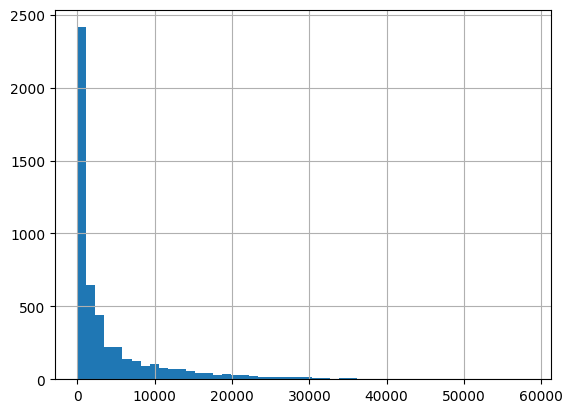

In [123]:
df = pd.read_sql("""
SELECT * FROM analysis
WHERE activity_met_min_week IS NOT NULL
""", conn)

print(df["activity_met_min_week"].describe())
print("Share at zero:", (df["activity_met_min_week"] == 0).mean())
df["activity_met_min_week"].hist(bins=50)

In [124]:
pd.read_sql("""
SELECT *
FROM analysis
WHERE activity_met_min_week IS NOT NULL
ORDER BY activity_met_min_week DESC
LIMIT 1
""", conn)

,seqn,age,age_group,sex,bmi,crp,hba1c,vigorous_work_minutes,moderate_work_minutes,walkbike_minutes,vigorous_rec_minutes,moderate_rec_minutes,sedentary_minutes,weight,psu,strata,activity_met_min_week
0,96299.0,29.0,18-39,male,20.9,7.87,4.6,3600.0,3600.0,0,1260.0,1260.0,30.0,68039.324126,1.0,145.0,58320.0


In [125]:
pd.read_sql("""
SELECT
    COUNT(*) AS n_flagged
FROM analysis
WHERE activity_met_min_week IS NOT NULL
    AND (vigorous_work_minutes + moderate_work_minutes
    + vigorous_rec_minutes + moderate_rec_minutes + walkbike_minutes) > 6720
""", conn)


,n_flagged
0,17


In [126]:
conn.execute("ALTER TABLE analysis ADD COLUMN implausible INTEGER")
conn.execute("""
UPDATE analysis
SET implausible = CASE
    WHEN (vigorous_work_minutes + moderate_work_minutes
    + vigorous_rec_minutes + moderate_rec_minutes + walkbike_minutes) > 6720 THEN 1
    ELSE 0
END
""")
conn.commit()

In [127]:
pd.read_sql("""
SELECT implausible, COUNT(*) AS n
FROM analysis
WHERE activity_met_min_week IS NOT NULL
GROUP BY implausible
""", conn)

,implausible,n
0,0,5081
1,1,17


In [130]:
pd.read_sql("""
SELECT
    CASE
        WHEN activity_met_min_week = 0 THEN '1: none'
        WHEN activity_met_min_week < 600 THEN '2: some, below guideline'
        WHEN activity_met_min_week < 1200 THEN '3: meets guideline'
        ELSE '4: well above guideline'
    END AS activity_group,
    COUNT(*) AS n,
    ROUND(AVG(crp), 2) AS mean_crp,
    ROUND(AVG(hba1c), 2) AS mean_hba1c
FROM analysis
WHERE activity_met_min_week IS NOT NULL
    AND implausible = 0
GROUP BY activity_group
ORDER By activity_group
""", conn)

,activity_group,n,mean_crp,mean_hba1c
0,1: none,1298,5.07,6.01
1,"2: some, below guideline",623,4.43,5.96
2,3: meets guideline,493,3.93,5.94
3,4: well above guideline,2667,3.71,5.70


In [131]:
pd.read_sql("""
SELECT
    age_group,
    CASE
        WHEN activity_met_min_week = 0   THEN '1: none'
        WHEN activity_met_min_week < 600  THEN '2: some, below guideline'
        WHEN activity_met_min_week < 1200 THEN '3: meets guideline'
        ELSE                                   '4: well above guideline'
    END AS activity_group,
    COUNT(*)             AS n,
    ROUND(AVG(crp), 2)   AS mean_crp,
    ROUND(AVG(hba1c), 2) AS mean_hba1c
FROM analysis
WHERE activity_met_min_week IS NOT NULL
  AND implausible = 0
GROUP BY age_group, activity_group
ORDER BY age_group, activity_group
""", conn)

,age_group,activity_group,n,mean_crp,mean_hba1c
0,18-39,1: none,269,4.45,5.42
1,18-39,"2: some, below guideline",146,3.82,5.44
2,18-39,3: meets guideline,123,3.88,5.34
3,18-39,4: well above guideline,1145,3.11,5.33
4,40-59,1: none,362,5.97,6.01
5,40-59,"2: some, below guideline",210,4.95,6.03
6,40-59,3: meets guideline,162,3.88,6.06
7,40-59,4: well above guideline,799,4.46,5.83
8,60-79,1: none,487,4.94,6.31
9,60-79,"2: some, below guideline",217,4.72,6.25


In [135]:
pd.read_sql("""
SELECT *
FROM (
    SELECT
        seqn,
        age_group,
        crp,
        ROUND(AVG(crp) OVER (PARTITION BY age_group), 2) AS age_group_mean_crp,
        ROUND(PERCENT_RANK() OVER (
            PARTITION BY age_group
            ORDER BY crp
        ), 3) AS crp_percentile_in_age_group,
        ROW_NUMBER() OVER (
                PARTITION BY age_group ORDER BY crp DESC
            ) AS rn
    FROM analysis
    WHERE activity_met_min_week IS NOT NULL
        AND implausible = 0
)
WHERE rn <= 5
ORDER BY age_group, rn
""", conn)

,seqn,age_group,crp,age_group_mean_crp,crp_percentile_in_age_group,rn
0,94353.0,18-39,80.09,3.44,1.000,1
1,94745.0,18-39,77.62,3.44,0.999,2
2,98345.0,18-39,63.70,3.44,0.999,3
3,97541.0,18-39,62.19,3.44,0.998,4
4,96400.0,18-39,51.48,3.44,0.998,5
5,96561.0,40-59,182.82,4.82,1.000,1
6,95641.0,40-59,138.81,4.82,0.999,2
7,99838.0,40-59,104.48,4.82,0.999,3
8,101052.0,40-59,90.51,4.82,0.998,4
9,99454.0,40-59,88.49,4.82,0.997,5
